In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

In [ ]:
data = pd.read_csv("student_performance_encoded.csv")

In [ ]:
# Separate input features
X = data[['Attendance','Hours_Studied','Sleep_Hours','Previous_Scores','Tutoring_Sessions','Motivation_Level','Parental_Involvement','Access_to_Resources']]
# Target variable
y = data['Exam_Score']

# Splitting the dataset into training data and testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

```
Choosing the correct model
```

In [ ]:
# Creating the model
linear_regression_model = LinearRegression()

# Training the model
linear_regression_model.fit(X_train, y_train)

# Predicting the exam scores
linear_regression_predictions = linear_regression_model.predict(X_test)

In [ ]:
# Creating the model
decision_tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)

# Training the model
decision_tree_model.fit(X_train, y_train)

# Predicting exam scores
decision_tree_predictions = decision_tree_model.predict(X_test)

In [28]:
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Train model
random_forest_model.fit(X_train, y_train)

# Predict exam scores
random_forest_predictions = random_forest_model.predict(X_test)

```
Checking Model Accuracy
```

In [29]:
# Calculating Mean Absolute Error (MAE) and R2 Score for all  models
linear_regression_mae = mean_absolute_error(y_test, linear_regression_predictions)
linear_regression_r2 = r2_score(y_test, linear_regression_predictions)

decision_tree_mae = mean_absolute_error(y_test, decision_tree_predictions)
decision_tree_r2 = r2_score(y_test, decision_tree_predictions)

random_forest_mae = mean_absolute_error(y_test, random_forest_predictions)
random_forest_r2 = r2_score(y_test, random_forest_predictions)

print(f"Linear Regression MAE: {linear_regression_mae:,.2f}, R2: {linear_regression_r2:,.2f}")
print(f"Decision Tree MAE: {decision_tree_mae:,.2f}, R2: {decision_tree_r2:,.2f}")
print(f"Random Forest MAE: {random_forest_mae:,.2f}, R2: {random_forest_r2:,.2f}")
# MAE lower is better, and R2 closer to 1 is better for predicting student exam scores.

Linear Regression MAE: 0.90, R2: 0.72
Decision Tree MAE: 1.60, R2: 0.55
Random Forest MAE: 1.42, R2: 0.60


```
Model Accuracy Visualization
```

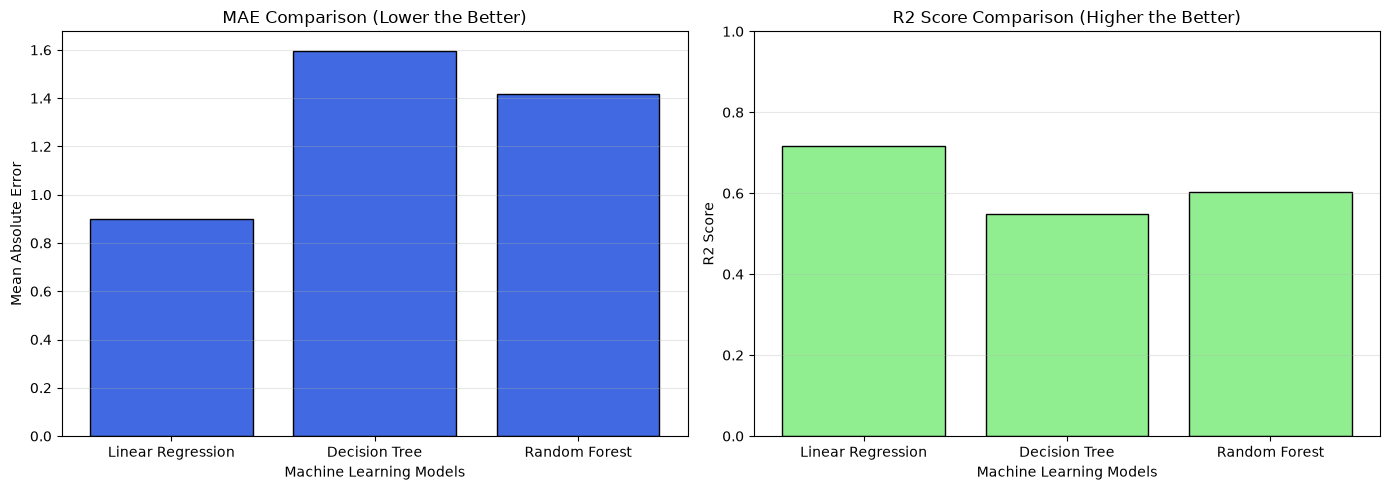

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Model names
model_names = ['Linear Regression', 'Decision Tree', 'Random Forest']

# MAE values
mae_values = [linear_regression_mae, decision_tree_mae, random_forest_mae]

# R2 values
r2_values = [linear_regression_r2, decision_tree_r2, random_forest_r2]


# 1. MAE Comparison
axes[0].bar(model_names, mae_values, color = 'royalblue', edgecolor='black')

axes[0].set_title('MAE Comparison (Lower the Better)')
axes[0].set_xlabel('Machine Learning Models')
axes[0].set_ylabel('Mean Absolute Error')
axes[0].grid(axis='y', alpha=0.3)


# 2. R2 Score Comparison
axes[1].bar(model_names, r2_values, color = 'lightgreen', edgecolor='black')

axes[1].set_title('R2 Score Comparison (Higher the Better)')
axes[1].set_xlabel('Machine Learning Models')
axes[1].set_ylabel('R2 Score')
axes[1].set_ylim(0, 1)
axes[1].grid(axis='y', alpha=0.3)


plt.tight_layout()
plt.show()

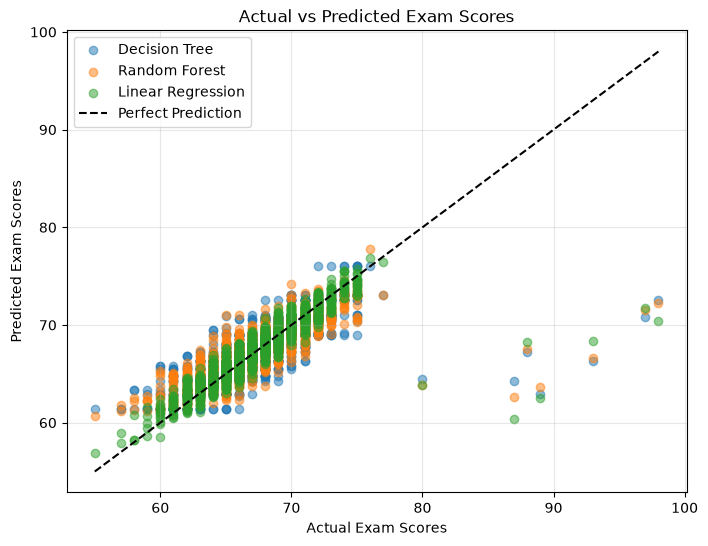

In [35]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, decision_tree_predictions,
            label='Decision Tree', alpha=0.5)

plt.scatter(y_test, random_forest_predictions,
            label='Random Forest', alpha=0.5)

plt.scatter(y_test, linear_regression_predictions,
            label='Linear Regression', alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'k--',
    label='Perfect Prediction'
)

plt.xlabel('Actual Exam Scores')
plt.ylabel('Predicted Exam Scores')
plt.title('Actual vs Predicted Exam Scores')

plt.legend()
plt.grid(alpha=0.3)
plt.show()